In [24]:
print("BMP Lab Ready")

BMP Lab Ready


In [25]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 1 — Setup & smoke test
# ══════════════════════════════════════════════════════════════════════════════
import importlib, matching
importlib.reload(matching)
from matching import (match_request, TIER_META, PRODUCT_META,
                      DEFAULT_CONFIG, TIER_RANK)

import random, math
random.seed(0)

CENTER_LAT, CENTER_LNG = 31.95, 35.91   # Amman city centre

# ── Display constants ──────────────────────────────────────────────────────────
TIER_COLORS    = {"economy": "#4C9BE8", "comfort": "#F5A623", "premium": "#7ED321"}
TIER_LABEL     = {"economy": "Starter",  "comfort": "Core",   "premium": "Pro"}
TIER_ORDER     = ["economy", "comfort", "premium"]
PRODUCT_COLORS = {"normal": "#7f8c8d", "comfort": "#e67e22"}
PRODUCT_LABEL  = {"normal": "Normal",   "comfort": "Comfort"}
PRODUCT_ORDER  = ["normal", "comfort"]

# ── Smoke test — Normal ride, 2 passengers ────────────────────────────────────
req_normal = {
    "pickup_lat": CENTER_LAT, "pickup_lng": CENTER_LNG,
    "dropoff_lat": CENTER_LAT + 0.04, "dropoff_lng": CENTER_LNG + 0.04,
    "product": "normal",          # ← rider-facing product: Normal or Comfort
    "pax_count": 2,
    "traffic_mult": 1.2,
    "rider_id": 999, "blacklisted_drivers": {7},
    "demand_lat": CENTER_LAT, "demand_lng": CENTER_LNG,
}
# Smoke test — Comfort ride (must dispatch Core or Pro only)
req_comfort = {**req_normal, "product": "comfort", "pax_count": 1}

drivers_test = [
    {"id": i,
     "lat": CENTER_LAT + random.uniform(-.06, .06),
     "lng": CENTER_LNG + random.uniform(-.06, .06),
     "available": True,
     "status": random.choice(["idle", "idle", "idle", "returning", "on_trip"]),
     "tiers": random.choice([["economy"],
                              ["economy", "comfort"],
                              ["economy", "comfort", "premium"]]),
     "trips_today": random.randint(0, 8),
     "assigned": random.randint(0, 12),
     "idle_min": random.uniform(0, 40),
     "shift_hours": random.uniform(0, 11),
     "offered": 50, "accepted": random.randint(35, 50),   # AR 70-100%
     "canceled": random.randint(0, 3),
     "on_time_rate": random.uniform(.78, 1.0),
     "rating": random.uniform(4.0, 5.0),                  # above normal floor
     "vehicle_rating": random.uniform(3.8, 5.0),
     "vehicle_seats": random.choice([4, 4, 4, 5, 6]),
     "heading_deg": random.uniform(0, 360),
     "speed_kmph_now": random.uniform(0, 30),
     "consecutive_declines": random.choices([0,0,0,0,1,2,4],
                                            weights=[50,20,12,8,5,3,2])[0],
    } for i in range(40)
]

for label, req in [("NORMAL", req_normal), ("COMFORT", req_comfort)]:
    best_id, ranked, debug = match_request(req, drivers_test, {})
    print(f"── {label} ride ──────────────────────────────────────────────────────────")
    if best_id is None:
        print(f"  No match: {debug.get('reason')}")
        continue
    print(f"  Best driver: {best_id}  |  Radius: {debug['radius_km']} km"
          f"  |  Candidates: {len(ranked)}")
    print(f"\n  {'Driver':>6}  {'Type':>16}  {'ETA':>5}  {'AR':>5}  {'Rat':>5}"
          f"  {'TierSig':>7}  {'Score':>7}  {'Cap':>7}")
    print("  " + "─"*68)
    for r in debug["top"][:5]:
        cap_str = (f"!{r['trips_today']}/{r['daily_cap']}" if r["above_cap"]
                   else f"{r['trips_today']}/{r['daily_cap']}")
        print(f"  {r['driver_id']:>6}  {r['driver_label']:>16}  {r['eta_min']:>5.1f}"
              f"  {r['acceptance_rate']:>5.3f}  {r['rating']:>5.2f}"
              f"  {r['tier_bonus_eff']:>7.3f}  {r['score']:>7.4f}  {cap_str:>7}")
    print()

# ── Hard-constraint unit tests ─────────────────────────────────────────────────
print("── Hard constraint tests ───────────────────────────────────────────────────")

# Comfort ride must not dispatch a Starter-only driver
only_starter = [{"id":0,"lat":CENTER_LAT,"lng":CENTER_LNG,"available":True,
                 "status":"idle","tiers":["economy"],"rating":4.8,
                 "vehicle_rating":4.5,"offered":30,"accepted":28,"canceled":0,
                 "on_time_rate":0.95,"vehicle_seats":4,"shift_hours":3,
                 "consecutive_declines":0}]
bid, _, _ = match_request(req_comfort, only_starter, {})
print(f"  Starter blocked from Comfort ride: {'PASS' if bid is None else 'FAIL'}")

# Blacklisted driver must not be dispatched
only_blacklisted = [{"id":7,"lat":CENTER_LAT,"lng":CENTER_LNG,"available":True,
                     "status":"idle","tiers":["economy","comfort","premium"],
                     "rating":4.9,"vehicle_rating":4.9,"offered":50,"accepted":49,
                     "canceled":0,"on_time_rate":1.0,"vehicle_seats":4,
                     "shift_hours":2,"consecutive_declines":0}]
bid, _, _ = match_request(req_normal, only_blacklisted, {})
print(f"  Blacklisted driver blocked:        {'PASS' if bid is None else 'FAIL'}")

# Low acceptance rate driver blocked from Comfort
low_ar = [{"id":1,"lat":CENTER_LAT,"lng":CENTER_LNG,"available":True,
           "status":"idle","tiers":["economy","comfort","premium"],
           "rating":4.8,"vehicle_rating":4.8,"offered":50,"accepted":30,   # AR=0.60
           "canceled":0,"on_time_rate":0.95,"vehicle_seats":4,"shift_hours":3,
           "consecutive_declines":0}]
bid, _, _ = match_request(req_comfort, low_ar, {})
print(f"  Low-AR driver blocked from Comfort: {'PASS' if bid is None else 'FAIL'}")

# Over-shift driver blocked
over_shift = [{"id":2,"lat":CENTER_LAT,"lng":CENTER_LNG,"available":True,
               "status":"idle","tiers":["economy","comfort","premium"],
               "rating":4.8,"vehicle_rating":4.5,"offered":50,"accepted":48,
               "canceled":0,"on_time_rate":0.9,"vehicle_seats":4,"shift_hours":15,
               "consecutive_declines":0}]
bid, _, _ = match_request(req_normal, over_shift, {})
print(f"  Over-shift driver blocked:          {'PASS' if bid is None else 'FAIL'}")


── NORMAL ride ──────────────────────────────────────────────────────────
  Best driver: 27  |  Radius: 8 km  |  Candidates: 14

  Driver              Type    ETA     AR    Rat  TierSig    Score      Cap
  ────────────────────────────────────────────────────────────────────
      27    Comfort Driver    1.9  0.900   4.65    0.150   2.8722      2/9
      12    Comfort Driver    4.0  0.980   4.16    0.300   2.6879     6/12
      20    Comfort Driver    2.9  0.800   4.12    0.150   2.4373      1/9
       8    Comfort Driver    8.8  0.860   4.65    0.300   1.9492     0/12
      38    Comfort Driver   11.3  0.860   4.40    0.300   1.8556     6/12

── COMFORT ride ──────────────────────────────────────────────────────────
  Best driver: 8  |  Radius: 8 km  |  Candidates: 1

  Driver              Type    ETA     AR    Rat  TierSig    Score      Cap
  ────────────────────────────────────────────────────────────────────
       8    Comfort Driver    8.8  0.860   4.65    0.300   1.9092     0/12


In [26]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 2 — Full simulation  (run this before any graph cells)
# ══════════════════════════════════════════════════════════════════════════════
import importlib, matching
importlib.reload(matching)
from matching import match_request, TIER_META, PRODUCT_META

import random, math
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

random.seed(42)

CENTER_LAT, CENTER_LNG = 31.95, 35.91
DEMAND_LAT, DEMAND_LNG = CENTER_LAT, CENTER_LNG

# ── Display constants ──────────────────────────────────────────────────────────
TIER_COLORS    = {"economy": "#4C9BE8", "comfort": "#F5A623", "premium": "#7ED321"}
TIER_LABEL     = {"economy": "Starter",  "comfort": "Core",   "premium": "Pro"}
TIER_ORDER     = ["economy", "comfort", "premium"]
PRODUCT_COLORS = {"normal": "#7f8c8d", "comfort": "#e67e22"}
PRODUCT_LABEL  = {"normal": "Normal",   "comfort": "Comfort"}
PRODUCT_ORDER  = ["normal", "comfort"]

# ── Uber-style config ──────────────────────────────────────────────────────────
config = {
    "max_radius_km":           8,
    "radius_expansion_factor": 1.5,
    "max_radius_expansions":   2,
    "max_candidates":          40,
    "speed_kmph":              24,
    # Tighter ETA cap makes ETA the dominant scoring factor (Uber-style)
    "eta_cap_min":             15,
    "shift_max_hours":         10,
    "max_shift_hours":         14,
    "fairness_cap":            10,
    "idle_cap_min":            30,
    # Consecutive decline penalty (Uber-style)
    "consec_decline_threshold": 3,
    "consec_decline_penalty":   0.60,
    # Wasel soft-cap
    "soft_cap":               {"economy": 6, "comfort": 9, "premium": 12},
    "soft_cap_penalty":        0.40,
    # Wasel tier preference (smaller bonus — ETA still dominates)
    "tier_bonus":             {"economy": 0.0, "comfort": 0.15, "premium": 0.30},
    "w_tier":                  0.8,
    "upgrade_bonus_per_level": 0.05,
    # Score weights — Uber-style: ETA first, acceptance rate second
    "w_eta":          2.0,   # PRIMARY
    "w_acceptance":   1.5,   # Uber's critical 2nd factor
    "w_rating":       0.8,
    "w_completion":   0.6,
    "w_on_time":      0.4,
    "w_idle":         0.3,
    "w_fairness":     0.3,
    "w_consec_decl":  0.5,
    "w_shift":        0.4,
    "w_heading":      0.2,
    "w_dead_mile":    0.15,
}

# ── Simulation parameters ──────────────────────────────────────────────────────
N_DRIVERS     = 600
N_DAYS        = 26       # operating days / month
TRIPS_PER_DAY = 180      # ride requests per day
N_REQUESTS    = N_DAYS * TRIPS_PER_DAY

# ── Driver factory ─────────────────────────────────────────────────────────────
# Fleet mix: Starter 45% (Normal Drivers) | Core 35% (Comfort Drivers)
#            Pro 20% (Comfort Drivers, highest priority)
# Each tier has higher baseline AR and rating than the tier below.
def make_driver(i):
    r = random.random()
    if r < 0.20:
        max_tier, tiers = "premium", ["economy", "comfort", "premium"]
        base_rating  = random.uniform(4.4, 5.0)
        base_vrating = random.uniform(4.2, 5.0)
        ar_rate      = random.uniform(0.72, 1.00)
    elif r < 0.55:
        max_tier, tiers = "comfort", ["economy", "comfort"]
        base_rating  = random.uniform(4.1, 5.0)
        base_vrating = random.uniform(3.8, 5.0)
        ar_rate      = random.uniform(0.62, 1.00)
    else:
        max_tier, tiers = "economy", ["economy"]
        base_rating  = random.uniform(3.4, 5.0)
        base_vrating = random.uniform(3.2, 5.0)
        ar_rate      = random.uniform(0.45, 0.95)

    off = random.randint(20, 80)
    acc = int(off * ar_rate)
    return {
        "id":                  i,
        "lat":                 CENTER_LAT + random.uniform(-0.12, 0.12),
        "lng":                 CENTER_LNG + random.uniform(-0.12, 0.12),
        "available":           True,
        "status":              "idle",
        "tiers":               tiers,
        "max_tier":            max_tier,
        # Reliability / history
        "offered":             off,
        "accepted":            acc,
        "canceled":            random.randint(0, max(0, acc // 5)),
        "on_time_rate":        random.uniform(0.72, 1.00),
        # Quality ratings
        "rating":              round(base_rating,  2),
        "vehicle_rating":      round(base_vrating, 2),
        "vehicle_seats":       random.choice([4, 4, 4, 5, 6]),
        # State
        "assigned":            0,
        "trips_today":         0,
        "idle_min":            random.uniform(0, 45),
        "shift_hours":         random.uniform(0, 8),
        "heading_deg":         random.uniform(0, 360),
        "speed_kmph_now":      0.0,
        # Uber-style consecutive decline tracking
        "consecutive_declines": random.choices(
            [0, 0, 0, 0, 1, 2, 3, 5],
            weights=[40, 18, 12, 10, 8, 6, 4, 2]
        )[0],
    }

# ── Request factory ────────────────────────────────────────────────────────────
# Ride product mix: Normal 70%  |  Comfort 30%
def make_request(t, rider_id):
    product = "comfort" if random.random() < 0.30 else "normal"
    plat = random.uniform(-0.12, 0.12)
    plng = random.uniform(-0.12, 0.12)
    dlat = CENTER_LAT + plat + random.uniform(-0.05, 0.05)
    dlng = CENTER_LNG + plng + random.uniform(-0.05, 0.05)
    pax  = random.choices([1, 2, 3, 4], weights=[55, 28, 12, 5])[0]
    return {
        "id":                  t,
        "rider_id":            rider_id,
        "pickup_lat":          CENTER_LAT + plat,
        "pickup_lng":          CENTER_LNG + plng,
        "dropoff_lat":         dlat,
        "dropoff_lng":         dlng,
        "product":             product,     # "normal" or "comfort"
        "pax_count":           pax,
        "traffic_mult":        min(1.0 + max(0.0, random.gauss(0.15, 0.20)), 2.2),
        "blacklisted_drivers": set(),
        "demand_lat":          DEMAND_LAT,
        "demand_lng":          DEMAND_LNG,
    }

# ── Run simulation ─────────────────────────────────────────────────────────────
drivers    = [make_driver(i) for i in range(N_DRIVERS)]
rider_pool = list(range(2000))
events     = []

for t in range(N_REQUESTS):
    day = t // TRIPS_PER_DAY + 1

    # Reset daily counters + update driver state at start of each day
    if t % TRIPS_PER_DAY == 0:
        for d in drivers:
            d["trips_today"]    = 0
            d["shift_hours"]   += 0.5
            d["heading_deg"]    = random.uniform(0, 360)
            d["speed_kmph_now"] = random.choice([0, 0, 0, 15, 25, 30])

    req     = make_request(t, random.choice(rider_pool))
    best_id, ranked_ids, debug = match_request(req, drivers, config)

    if best_id is None:
        events.append({
            "t": t, "day": day,
            "req_product": req["product"],
            "pax_count":   req["pax_count"],
            "matched":     0,
            "driver_id":   None, "driver_tier": None,
            "above_cap":   None, "eta_min":     None,
            "driver_rating":     None,
            "driver_acceptance": None,
            "attempts":    debug.get("attempts", 1),
        })
        continue

    d   = drivers[best_id]
    top = debug["top"][0]

    # Update dispatched driver state
    d["assigned"]            += 1
    d["trips_today"]         += 1
    d["idle_min"]             = 0.0
    d["consecutive_declines"] = 0     # reset after accepted ride
    d["speed_kmph_now"]       = 25.0
    d["heading_deg"]          = math.degrees(
        math.atan2(req["dropoff_lng"] - d["lng"],
                   req["dropoff_lat"] - d["lat"])) % 360

    # Other drivers wait longer, slow down
    for o in drivers:
        if o["id"] != best_id:
            o["idle_min"]        = min(o["idle_min"] + 0.05, 90)
            o["speed_kmph_now"]  = max(o["speed_kmph_now"] - 1, 0)

    events.append({
        "t":                 t,
        "day":               day,
        "req_product":       req["product"],
        "pax_count":         req["pax_count"],
        "matched":           1,
        "driver_id":         best_id,
        "driver_tier":       d["max_tier"],
        "above_cap":         top["above_cap"],
        "eta_min":           top["eta_min"],
        "driver_rating":     top["rating"],
        "driver_acceptance": top["acceptance_rate"],
        "attempts":          debug["attempts"],
    })

df      = pd.DataFrame(events)
matched = df[df["matched"] == 1].copy()

# ── Results ────────────────────────────────────────────────────────────────────
print("═" * 55)
print(f" WASEL BMP v3.0 — Uber-style Dispatch Simulation")
print("═" * 55)
print(f" Days: {N_DAYS}  |  Drivers: {N_DRIVERS}  |  Requests: {N_REQUESTS:,}")
print("─" * 55)
print(f" Overall match rate : {df['matched'].mean():.3f}")
print(f" Avg ETA (matched)  : {matched['eta_min'].mean():.1f} min")
print(f" Multi-attempt %    : {(matched['attempts']>1).mean()*100:.1f}%")
print(f" Above-cap %        : {matched['above_cap'].mean()*100:.1f}%")
print()
print(" BY PRODUCT:")
for p in PRODUCT_ORDER:
    pm = df[df["req_product"] == p]
    if pm.empty: continue
    eta_str = (f"avg ETA {pm[pm['matched']==1]['eta_min'].mean():.1f} min"
               if pm["matched"].sum() > 0 else "no matches")
    print(f"   {PRODUCT_LABEL[p]:7s}  {len(pm):>5,} req  "
          f"match {pm['matched'].mean():.3f}  {eta_str}")
print()
print(" DRIVER DISPATCH:")
tc = matched["driver_tier"].value_counts().reindex(TIER_ORDER).fillna(0)
fleet_pct = {"economy": 45, "comfort": 35, "premium": 20}
for t in TIER_ORDER:
    pct = tc[t] / tc.sum() * 100
    label = TIER_META[t]["driver_label"]
    print(f"   {TIER_LABEL[t]:7s} ({label:>15s}, fleet {fleet_pct[t]}%): "
          f"{tc[t]:.0f} rides  ({pct:.1f}% dispatch)")
print("═" * 55)
df.tail(4)


═══════════════════════════════════════════════════════
 WASEL BMP v3.0 — Uber-style Dispatch Simulation
═══════════════════════════════════════════════════════
 Days: 26  |  Drivers: 600  |  Requests: 4,680
───────────────────────────────────────────────────────
 Overall match rate : 0.988
 Avg ETA (matched)  : 3.5 min
 Multi-attempt %    : 0.0%
 Above-cap %        : 0.0%

 BY PRODUCT:
   Normal   3,308 req  match 1.000  avg ETA 3.0 min
   Comfort  1,372 req  match 0.961  avg ETA 4.6 min

 DRIVER DISPATCH:
   Starter (  Normal Driver, fleet 45%): 506 rides  (10.9% dispatch)
   Core    ( Comfort Driver, fleet 35%): 1896 rides  (41.0% dispatch)
   Pro     ( Comfort Driver, fleet 20%): 2224 rides  (48.1% dispatch)
═══════════════════════════════════════════════════════


,t,day,req_product,pax_count,matched,driver_id,driver_tier,above_cap,eta_min,driver_rating,driver_acceptance,attempts
4676,4676,26,normal,1,1,449.0,comfort,True,11.56,4.43,0.887,1
4677,4677,26,comfort,1,1,526.0,premium,False,3.69,4.97,0.985,1
4678,4678,26,normal,1,1,297.0,premium,False,4.32,4.71,0.762,1
4679,4679,26,normal,1,1,430.0,comfort,False,12.70,4.68,0.775,1


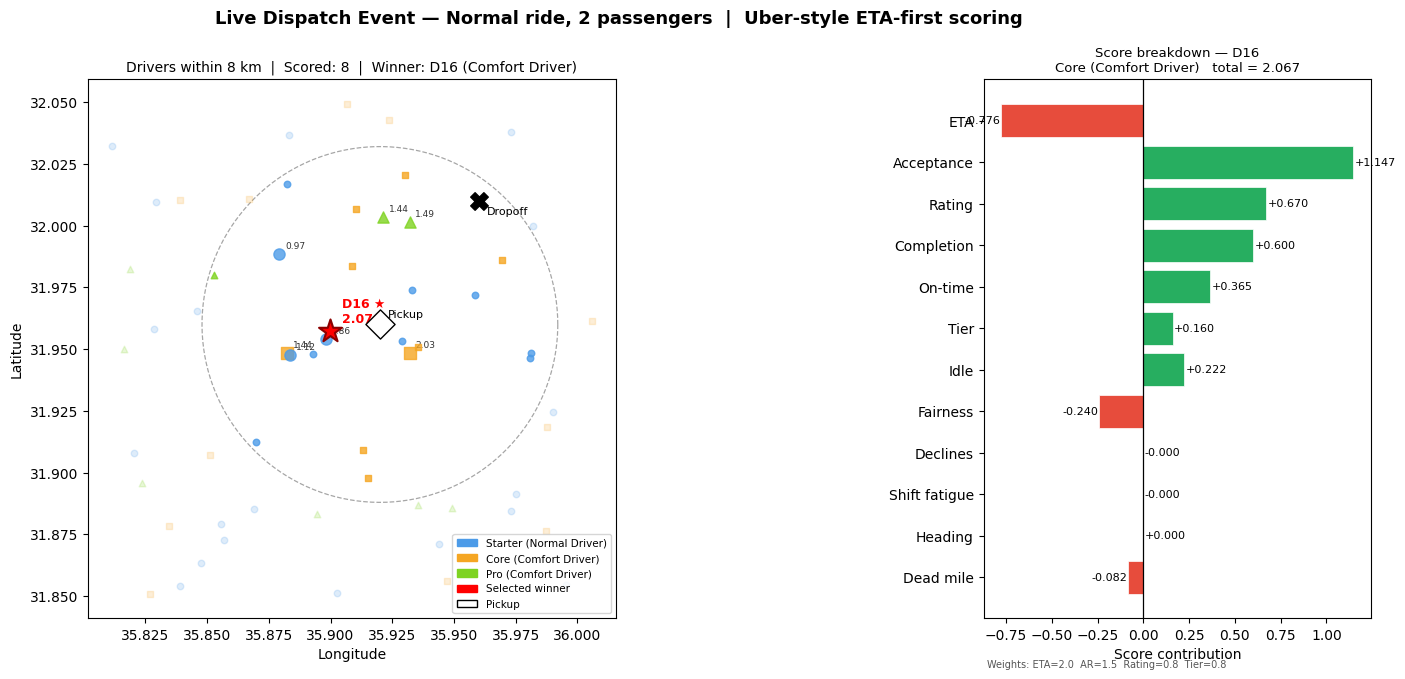


Top 5 candidates — Normal ride, 2 pax

     D             Type    ETA     AR    Rat   Tier    Score  Declines
  ──────────────────────────────────────────────────────────────────────
    16   Comfort Driver    5.8  0.765   4.12  0.150   2.0670  1 (7/9)
     9   Comfort Driver    5.2  0.741   4.19  0.150   2.0275  0 (1/9)
    12    Normal Driver    6.5  0.733   4.75  0.000   1.8583  0 (0/6)
    53   Comfort Driver   14.2  0.958   4.41  0.300   1.4888  0 (4/12)
    37   Comfort Driver   14.6  0.787   4.90  0.300   1.4446  0 (1/12)


In [27]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 3 — Live dispatch event: geographic map + score waterfall
# ══════════════════════════════════════════════════════════════════════════════
import importlib, matching
importlib.reload(matching)
from matching import match_request, TIER_META, PRODUCT_META

import numpy as np, math, random
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches

TIER_COLORS    = {"economy": "#4C9BE8", "comfort": "#F5A623", "premium": "#7ED321"}
TIER_LABEL     = {"economy": "Starter",  "comfort": "Core",   "premium": "Pro"}
TIER_ORDER     = ["economy", "comfort", "premium"]
PRODUCT_COLORS = {"normal": "#7f8c8d", "comfort": "#e67e22"}
PRODUCT_LABEL  = {"normal": "Normal",   "comfort": "Comfort"}
CENTER_LAT, CENTER_LNG = 31.95, 35.91

# ── Build a small local fleet for the demo ─────────────────────────────────────
random.seed(12)
demo_drivers = []
for i in range(60):
    r = random.random()
    if r < 0.20:
        mt, tiers = "premium", ["economy","comfort","premium"]
        rat, vrat = random.uniform(4.4,5.0), random.uniform(4.2,5.0)
        ar = random.uniform(0.75, 1.00)
    elif r < 0.55:
        mt, tiers = "comfort",  ["economy","comfort"]
        rat, vrat = random.uniform(4.1,5.0), random.uniform(3.8,5.0)
        ar = random.uniform(0.65, 1.00)
    else:
        mt, tiers = "economy",  ["economy"]
        rat, vrat = random.uniform(3.5,5.0), random.uniform(3.2,5.0)
        ar = random.uniform(0.50, 0.95)

    off = random.randint(20, 60)
    acc = int(off * ar)
    demo_drivers.append({
        "id": i,
        "lat": CENTER_LAT + random.uniform(-.10, .10),
        "lng": CENTER_LNG + random.uniform(-.10, .10),
        "available": True,
        "status": random.choice(["idle","idle","returning"]),
        "tiers": tiers, "max_tier": mt,
        "offered": off, "accepted": acc,
        "canceled": random.randint(0, max(0, acc // 5)),
        "on_time_rate": random.uniform(.75, 1.0),
        "rating": round(rat, 2), "vehicle_rating": round(vrat, 2),
        "vehicle_seats": random.choice([4,4,5,6]),
        "assigned": random.randint(0, 8),
        "trips_today": random.randint(0, 7),
        "idle_min": random.uniform(0, 35),
        "shift_hours": random.uniform(0, 9),
        "heading_deg": random.uniform(0, 360),
        "speed_kmph_now": random.choice([0,0,15,25]),
        "consecutive_declines": random.choices([0,0,0,1,2,4],
                                               weights=[50,20,12,8,6,4])[0],
    })

# Demo request — Normal ride, 2 passengers
demo_req = {
    "pickup_lat":  CENTER_LAT + 0.01,
    "pickup_lng":  CENTER_LNG + 0.01,
    "dropoff_lat": CENTER_LAT + 0.06,
    "dropoff_lng": CENTER_LNG + 0.05,
    "product": "normal",
    "pax_count": 2,
    "traffic_mult": 1.2,
    "blacklisted_drivers": set(),
    "demand_lat": CENTER_LAT, "demand_lng": CENTER_LNG,
}

best_id, ranked_ids, debug = match_request(demo_req, demo_drivers, config)
top_rows  = debug["top"][:8]
score_map = {r["driver_id"]: r["score"] for r in debug["top"]}

fig = plt.figure(figsize=(16, 7))
fig.suptitle(
    f"Live Dispatch Event — {PRODUCT_LABEL[demo_req['product']]} ride, "
    f"{demo_req['pax_count']} passengers  |  Uber-style ETA-first scoring",
    fontsize=13, fontweight="bold"
)
gs = gridspec.GridSpec(1, 3, figure=fig, wspace=0.42, left=0.04, right=0.97)

# ── Left: geographic map ───────────────────────────────────────────────────────
ax_map = fig.add_subplot(gs[0, :2])
all_scored = set(r["driver_id"] for r in debug["top"])

for d in demo_drivers:
    tier = d["max_tier"]
    dist = math.sqrt((d["lat"] - demo_req["pickup_lat"])**2 +
                     (d["lng"] - demo_req["pickup_lng"])**2) * 111
    in_radius = dist < config["max_radius_km"]
    if d["id"] == best_id:
        continue
    alpha  = 0.80 if in_radius else 0.18
    marker = "^" if tier == "premium" else "s" if tier == "comfort" else "o"
    sz     = 65 if d["id"] in all_scored else 22
    ax_map.scatter(d["lng"], d["lat"], c=TIER_COLORS[tier],
                   marker=marker, s=sz, alpha=alpha, zorder=3)
    if d["id"] in all_scored:
        sc = score_map[d["id"]]
        ax_map.annotate(f"{sc:.2f}", (d["lng"], d["lat"]),
                        textcoords="offset points", xytext=(4,4),
                        fontsize=6.5, color="#333")

# Winner
winner = next(d for d in demo_drivers if d["id"] == best_id)
ax_map.scatter(winner["lng"], winner["lat"], c="red", s=300,
               marker="*", zorder=6, edgecolors="darkred", lw=1.5)
ax_map.annotate(f"D{best_id} ★\n{score_map[best_id]:.2f}",
                (winner["lng"], winner["lat"]),
                textcoords="offset points", xytext=(9, 6),
                fontsize=9, fontweight="bold", color="red")

# Pickup & dropoff markers
ax_map.scatter(demo_req["pickup_lng"], demo_req["pickup_lat"],
               c="white", edgecolors="black", s=220, marker="D", zorder=5)
ax_map.scatter(demo_req["dropoff_lng"], demo_req["dropoff_lat"],
               c="black", marker="X", s=160, zorder=5)
ax_map.annotate("Pickup",  (demo_req["pickup_lng"],  demo_req["pickup_lat"]),
                textcoords="offset points", xytext=(6, 5), fontsize=8)
ax_map.annotate("Dropoff", (demo_req["dropoff_lng"], demo_req["dropoff_lat"]),
                textcoords="offset points", xytext=(6, -10), fontsize=8)

# Search radius circle
deg = 1/111.0; theta = np.linspace(0, 2*math.pi, 300)
r_km = config["max_radius_km"] * deg
ax_map.plot(demo_req["pickup_lng"] + r_km*np.cos(theta),
            demo_req["pickup_lat"] + r_km*np.sin(theta),
            "k--", lw=0.9, alpha=0.35)

legend_p = [mpatches.Patch(color=TIER_COLORS[t], label=f"{TIER_LABEL[t]} ({TIER_META[t]['driver_label']})")
            for t in TIER_ORDER]
legend_p += [mpatches.Patch(color="red", label="Selected winner"),
             mpatches.Patch(color="white", ec="black", label="Pickup")]
ax_map.legend(handles=legend_p, fontsize=7.5, loc="lower right")
ax_map.set_title(
    f"Drivers within {config['max_radius_km']} km  |  Scored: {len(debug['top'])}  "
    f"|  Winner: D{best_id} ({TIER_META[winner['max_tier']]['driver_label']})",
    fontsize=10
)
ax_map.set_xlabel("Longitude"); ax_map.set_ylabel("Latitude")
ax_map.set_aspect("equal")

# ── Right: score waterfall for winning driver ──────────────────────────────────
ax_w = fig.add_subplot(gs[0, 2])
contrib = debug["top"][0]["_contrib"]
keys    = list(contrib.keys())
vals    = list(contrib.values())
colors  = ["#E74C3C" if v < 0 else "#27AE60" for v in vals]

bars = ax_w.barh(keys[::-1], vals[::-1], color=colors[::-1],
                 edgecolor="white", lw=0.5)
ax_w.axvline(0, color="black", lw=0.9)
for bar, v in zip(bars, vals[::-1]):
    offset = 0.007 if v >= 0 else -0.007
    ha     = "left" if v >= 0 else "right"
    ax_w.text(v + offset, bar.get_y() + bar.get_height()/2,
              f"{v:+.3f}", va="center", ha=ha, fontsize=8)

ax_w.set_title(
    f"Score breakdown — D{best_id}\n"
    f"{TIER_META[winner['max_tier']]['name']} ({TIER_META[winner['max_tier']]['driver_label']})"
    f"   total = {score_map[best_id]:.3f}",
    fontsize=9.5
)
ax_w.set_xlabel("Score contribution")
# Add note on weights
w = config
ax_w.text(0.01, -0.09,
          f"Weights: ETA={w['w_eta']}  AR={w['w_acceptance']}  Rating={w['w_rating']}  "
          f"Tier={w['w_tier']}",
          transform=ax_w.transAxes, fontsize=7, color="#555")

plt.show()

# ── Print top 5 candidates ─────────────────────────────────────────────────────
print(f"\nTop 5 candidates — Normal ride, 2 pax\n")
print(f"  {'D':>4}  {'Type':>15}  {'ETA':>5}  {'AR':>5}  {'Rat':>5}  "
      f"{'Tier':>5}  {'Score':>7}  Declines")
print("  " + "─"*70)
for r in debug["top"][:5]:
    cap_str = f"{'!' if r['above_cap'] else ''}{r['trips_today']}/{r['daily_cap']}"
    print(f"  {r['driver_id']:>4}  {r['driver_label']:>15}  {r['eta_min']:>5.1f}"
          f"  {r['acceptance_rate']:>5.3f}  {r['rating']:>5.2f}"
          f"  {r['tier_bonus_eff']:>5.3f}  {r['score']:>7.4f}"
          f"  {r['consecutive_declines']} ({cap_str})")


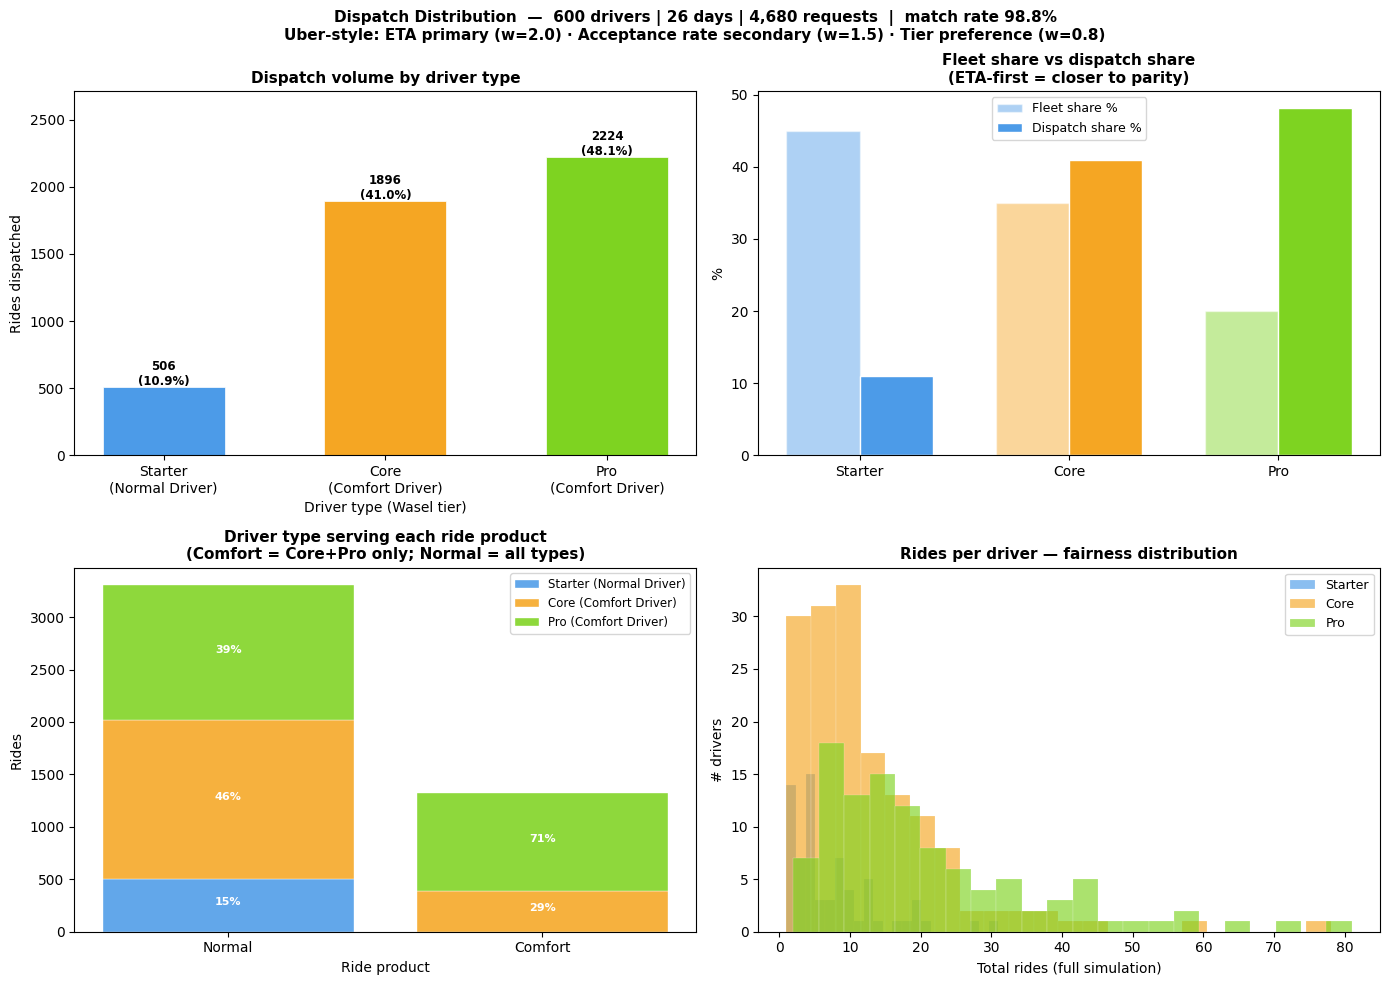

In [28]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 4 — Dispatch distribution charts
# ══════════════════════════════════════════════════════════════════════════════
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matching import TIER_META

TIER_COLORS    = {"economy": "#4C9BE8", "comfort": "#F5A623", "premium": "#7ED321"}
TIER_LABEL     = {"economy": "Starter",  "comfort": "Core",   "premium": "Pro"}
TIER_ORDER     = ["economy", "comfort", "premium"]
PRODUCT_COLORS = {"normal": "#7f8c8d", "comfort": "#e67e22"}
PRODUCT_LABEL  = {"normal": "Normal",   "comfort": "Comfort"}
PRODUCT_ORDER  = ["normal", "comfort"]

matched     = df[df["matched"] == 1].copy()
tier_counts = matched["driver_tier"].value_counts().reindex(TIER_ORDER).fillna(0)
fleet_pct   = {"economy": 45, "comfort": 35, "premium": 20}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(
    f"Dispatch Distribution  —  {N_DRIVERS} drivers | {N_DAYS} days | "
    f"{N_REQUESTS:,} requests  |  match rate {df['matched'].mean():.1%}\n"
    f"Uber-style: ETA primary (w=2.0) · Acceptance rate secondary (w=1.5) · "
    f"Tier preference (w=0.8)",
    fontsize=11, fontweight="bold"
)

# ── 1. Dispatch volume by driver type ─────────────────────────────────────────
ax = axes[0, 0]
driver_labels = [f"{TIER_LABEL[t]}\n({TIER_META[t]['driver_label']})" for t in TIER_ORDER]
bars = ax.bar(driver_labels, tier_counts.values,
              color=[TIER_COLORS[t] for t in TIER_ORDER],
              edgecolor="white", lw=0.5, width=0.55)
for bar, t, v in zip(bars, TIER_ORDER, tier_counts.values):
    d_pct = v / tier_counts.sum() * 100
    ax.text(bar.get_x() + bar.get_width()/2, v + 15,
            f"{v:.0f}\n({d_pct:.1f}%)", ha="center", fontsize=8.5, fontweight="bold")
ax.set_title("Dispatch volume by driver type", fontsize=11, fontweight="bold")
ax.set_ylabel("Rides dispatched")
ax.set_ylim(0, tier_counts.max() * 1.22)
ax.set_xlabel("Driver type (Wasel tier)")

# ── 2. Fleet share vs dispatch share ──────────────────────────────────────────
ax2 = axes[0, 1]
x = np.arange(3); w = 0.35
ax2.bar(x - w/2, [fleet_pct[t] for t in TIER_ORDER], w,
        label="Fleet share %",
        color=[TIER_COLORS[t] for t in TIER_ORDER], alpha=0.45, edgecolor="white")
ax2.bar(x + w/2, [tier_counts[t] / tier_counts.sum() * 100 for t in TIER_ORDER], w,
        label="Dispatch share %",
        color=[TIER_COLORS[t] for t in TIER_ORDER], edgecolor="white")
ax2.set_xticks(x)
ax2.set_xticklabels([f"{TIER_LABEL[t]}" for t in TIER_ORDER])
ax2.set_ylabel("%"); ax2.legend(fontsize=9)
ax2.set_title("Fleet share vs dispatch share\n(ETA-first = closer to parity)",
              fontsize=11, fontweight="bold")

# ── 3. Who served each ride product (stacked bars) ────────────────────────────
ax3 = axes[1, 0]
# For each product, show which driver tiers served it
ct = (pd.crosstab(matched["req_product"], matched["driver_tier"])
      .reindex(index=PRODUCT_ORDER, columns=TIER_ORDER).fillna(0))

x3 = np.arange(len(PRODUCT_ORDER))
bottom = np.zeros(len(PRODUCT_ORDER))
for dtier in TIER_ORDER:
    vals = ct[dtier].values if dtier in ct.columns else np.zeros(len(PRODUCT_ORDER))
    ax3.bar([PRODUCT_LABEL[p] for p in PRODUCT_ORDER], vals,
            bottom=bottom, color=TIER_COLORS[dtier],
            label=f"{TIER_LABEL[dtier]} ({TIER_META[dtier]['driver_label']})",
            alpha=0.88, edgecolor="white", lw=0.3)
    for xi, (v, b) in enumerate(zip(vals, bottom)):
        if v > 20:
            pct = v / (ct.sum(axis=1).iloc[xi]) * 100
            ax3.text(xi, b + v/2, f"{pct:.0f}%", ha="center",
                     fontsize=8, color="white", fontweight="bold")
    bottom += vals

ax3.set_title("Driver type serving each ride product\n"
              "(Comfort = Core+Pro only; Normal = all types)",
              fontsize=11, fontweight="bold")
ax3.set_xlabel("Ride product"); ax3.set_ylabel("Rides")
ax3.legend(fontsize=8.5, loc="upper right")

# ── 4. Rides-per-driver distribution by tier ──────────────────────────────────
ax4 = axes[1, 1]
assigned_by_id  = matched.groupby("driver_id").size()
driver_tier_map = {d["id"]: d["max_tier"] for d in drivers}
ts = assigned_by_id.reset_index(); ts.columns = ["driver_id", "rides"]
ts["tier"] = ts["driver_id"].map(driver_tier_map)
for tier in TIER_ORDER:
    vals = ts[ts["tier"] == tier]["rides"]
    if not vals.empty:
        ax4.hist(vals, bins=22, alpha=0.65, label=TIER_LABEL[tier],
                 color=TIER_COLORS[tier], edgecolor="white", lw=0.2)
ax4.set_title("Rides per driver — fairness distribution",
              fontsize=11, fontweight="bold")
ax4.set_xlabel("Total rides (full simulation)")
ax4.set_ylabel("# drivers")
ax4.legend(fontsize=9)

plt.tight_layout()
plt.show()


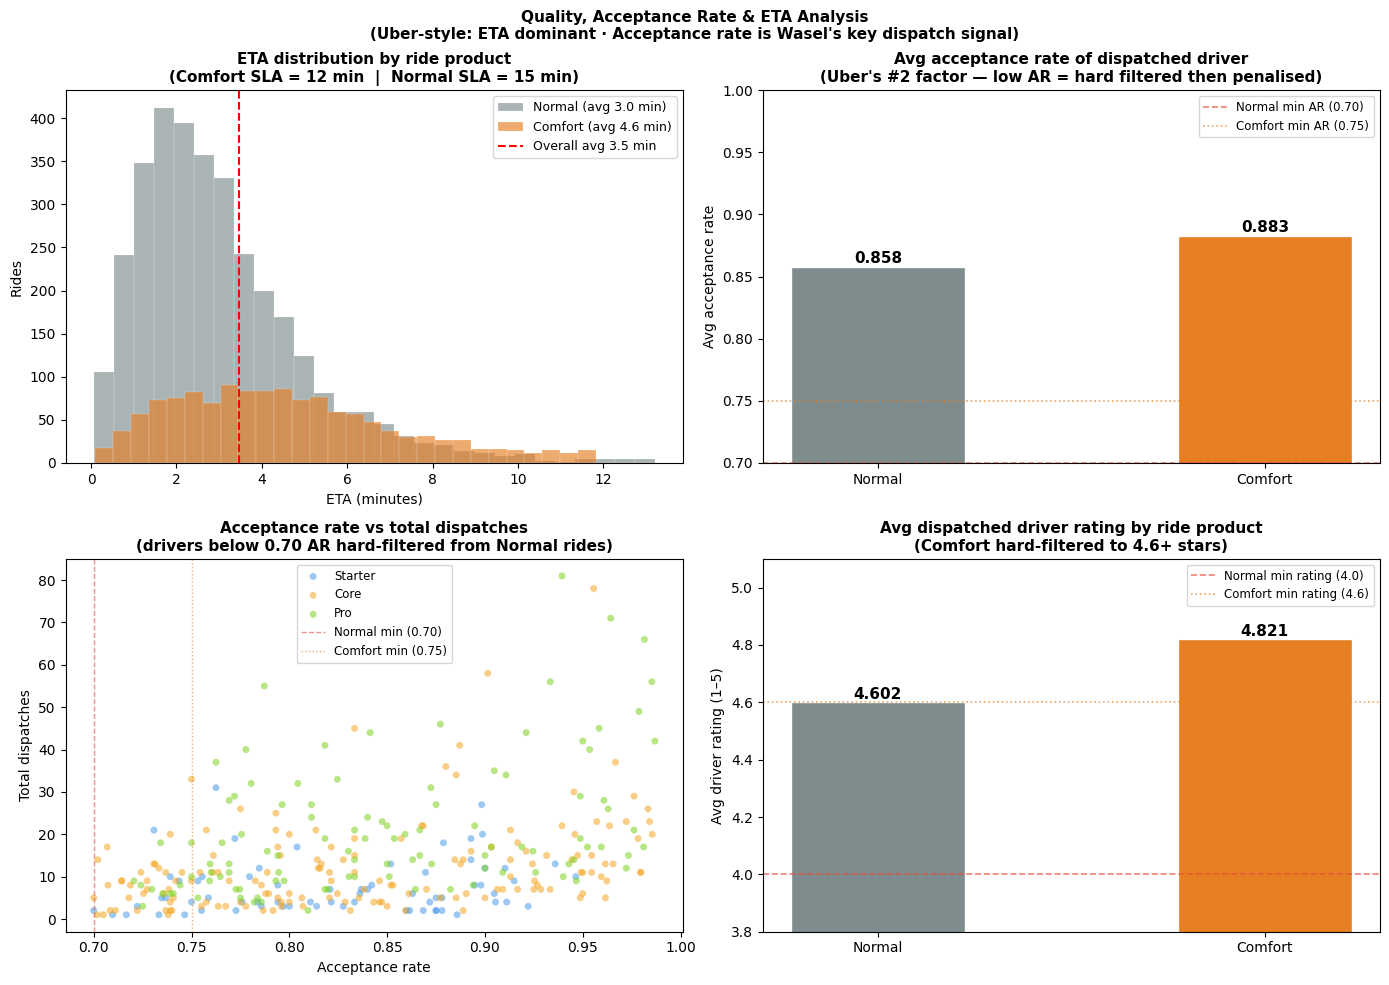

In [29]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 5 — Quality, acceptance rate & ETA analysis
# ══════════════════════════════════════════════════════════════════════════════
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

TIER_COLORS    = {"economy": "#4C9BE8", "comfort": "#F5A623", "premium": "#7ED321"}
TIER_LABEL     = {"economy": "Starter",  "comfort": "Core",   "premium": "Pro"}
TIER_ORDER     = ["economy", "comfort", "premium"]
PRODUCT_COLORS = {"normal": "#7f8c8d", "comfort": "#e67e22"}
PRODUCT_LABEL  = {"normal": "Normal",   "comfort": "Comfort"}
PRODUCT_ORDER  = ["normal", "comfort"]

matched = df[df["matched"] == 1].copy()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Quality, Acceptance Rate & ETA Analysis\n"
             "(Uber-style: ETA dominant · Acceptance rate is Wasel's key dispatch signal)",
             fontsize=11, fontweight="bold")

# ── 1. ETA distribution by ride product ───────────────────────────────────────
ax = axes[0, 0]
for p in PRODUCT_ORDER:
    vals = matched[matched["req_product"] == p]["eta_min"].dropna()
    if not vals.empty:
        ax.hist(vals, bins=28, alpha=0.65,
                label=f"{PRODUCT_LABEL[p]} (avg {vals.mean():.1f} min)",
                color=PRODUCT_COLORS[p], edgecolor="white", lw=0.2)
ax.axvline(matched["eta_min"].mean(), color="red", lw=1.5, ls="--",
           label=f"Overall avg {matched['eta_min'].mean():.1f} min")
ax.set_title("ETA distribution by ride product\n"
             "(Comfort SLA = 12 min  |  Normal SLA = 15 min)",
             fontsize=11, fontweight="bold")
ax.set_xlabel("ETA (minutes)"); ax.set_ylabel("Rides")
ax.legend(fontsize=9)

# ── 2. Avg driver acceptance rate dispatched by ride product ──────────────────
ax2 = axes[0, 1]
avg_ar = matched.groupby("req_product")["driver_acceptance"].mean().reindex(PRODUCT_ORDER)
bars   = ax2.bar([PRODUCT_LABEL[p] for p in PRODUCT_ORDER], avg_ar.values,
                 color=[PRODUCT_COLORS[p] for p in PRODUCT_ORDER], edgecolor="white",
                 width=0.45)
for bar, v in zip(bars, avg_ar.values):
    ax2.text(bar.get_x() + bar.get_width()/2, v + 0.003,
             f"{v:.3f}", ha="center", fontsize=11, fontweight="bold")
ax2.set_ylim(0.70, 1.0)
ax2.axhline(0.70, color="#e74c3c", lw=1.2, ls="--", alpha=0.7,
            label="Normal min AR (0.70)")
ax2.axhline(0.75, color="#e67e22", lw=1.2, ls=":", alpha=0.7,
            label="Comfort min AR (0.75)")
ax2.legend(fontsize=8.5)
ax2.set_title("Avg acceptance rate of dispatched driver\n"
              "(Uber's #2 factor — low AR = hard filtered then penalised)",
              fontsize=11, fontweight="bold")
ax2.set_ylabel("Avg acceptance rate")

# ── 3. Acceptance rate vs total dispatches scatter ────────────────────────────
ax3 = axes[1, 0]
driver_tier_map = {d["id"]: d["max_tier"] for d in drivers}
driver_ar_map   = {d["id"]: (d["accepted"] / max(d["offered"], 1)) for d in drivers}
dispatch_counts = matched.groupby("driver_id").size()
for tier in TIER_ORDER:
    ids   = [d["id"] for d in drivers if d["max_tier"] == tier
             and d["id"] in dispatch_counts]
    ars   = [driver_ar_map[i] for i in ids]
    rides = [dispatch_counts[i] for i in ids]
    ax3.scatter(ars, rides, c=TIER_COLORS[tier], label=TIER_LABEL[tier],
                alpha=0.55, s=25, edgecolors="none")
ax3.axvline(0.70, color="#e74c3c", lw=1, ls="--", alpha=0.6,
            label="Normal min (0.70)")
ax3.axvline(0.75, color="#e67e22", lw=1, ls=":", alpha=0.6,
            label="Comfort min (0.75)")
ax3.set_title("Acceptance rate vs total dispatches\n"
              "(drivers below 0.70 AR hard-filtered from Normal rides)",
              fontsize=11, fontweight="bold")
ax3.set_xlabel("Acceptance rate"); ax3.set_ylabel("Total dispatches")
ax3.legend(fontsize=8.5)

# ── 4. Avg dispatched driver rating by ride product ───────────────────────────
ax4 = axes[1, 1]
avg_rat = matched.groupby("req_product")["driver_rating"].mean().reindex(PRODUCT_ORDER)
bars    = ax4.bar([PRODUCT_LABEL[p] for p in PRODUCT_ORDER], avg_rat.values,
                  color=[PRODUCT_COLORS[p] for p in PRODUCT_ORDER], edgecolor="white",
                  width=0.45)
for bar, v in zip(bars, avg_rat.values):
    ax4.text(bar.get_x() + bar.get_width()/2, v + 0.01,
             f"{v:.3f}", ha="center", fontsize=11, fontweight="bold")
ax4.axhline(4.0, color="#e74c3c", lw=1.2, ls="--", alpha=0.7,
            label="Normal min rating (4.0)")
ax4.axhline(4.6, color="#e67e22", lw=1.2, ls=":", alpha=0.7,
            label="Comfort min rating (4.6)")
ax4.legend(fontsize=8.5)
ax4.set_ylim(3.8, 5.1)
ax4.set_title("Avg dispatched driver rating by ride product\n"
              "(Comfort hard-filtered to 4.6+ stars)",
              fontsize=11, fontweight="bold")
ax4.set_ylabel("Avg driver rating (1–5)")

plt.tight_layout()
plt.show()


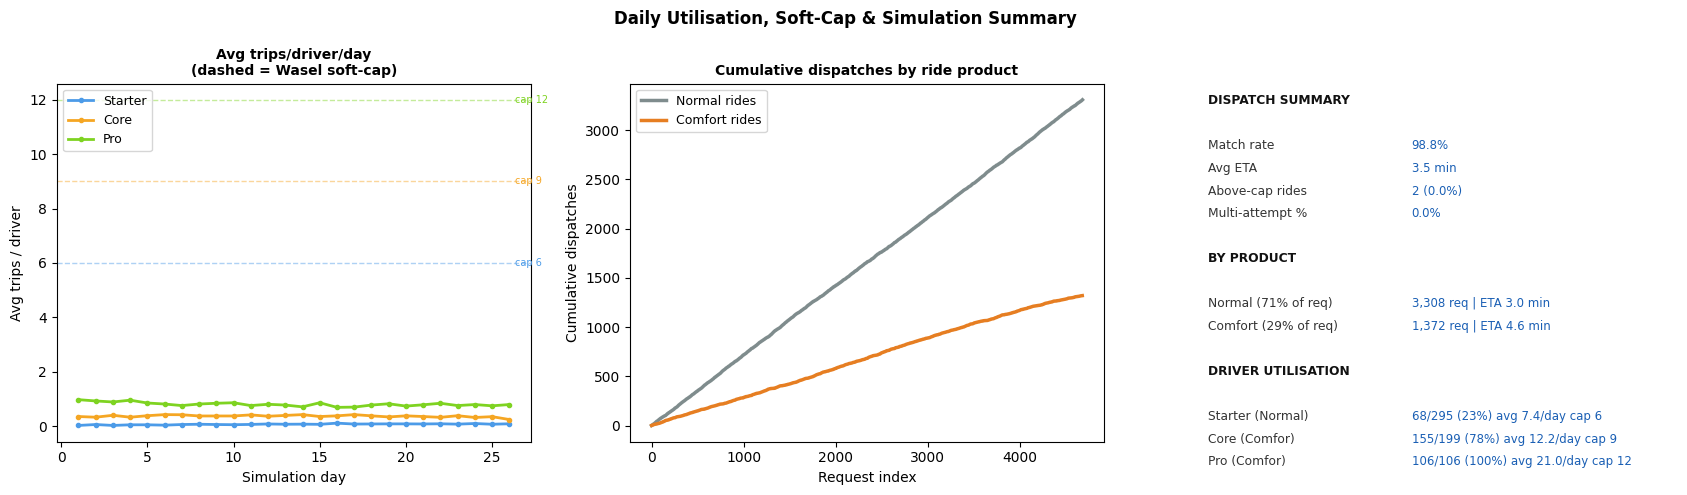

In [30]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 6 — Daily utilisation, soft-cap & summary stats
# ══════════════════════════════════════════════════════════════════════════════
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from matching import TIER_META

TIER_COLORS    = {"economy": "#4C9BE8", "comfort": "#F5A623", "premium": "#7ED321"}
TIER_LABEL     = {"economy": "Starter",  "comfort": "Core",   "premium": "Pro"}
TIER_ORDER     = ["economy", "comfort", "premium"]
PRODUCT_COLORS = {"normal": "#7f8c8d", "comfort": "#e67e22"}
PRODUCT_LABEL  = {"normal": "Normal",   "comfort": "Comfort"}
PRODUCT_ORDER  = ["normal", "comfort"]

matched       = df[df["matched"] == 1].copy()
n_per_tier    = {t: sum(1 for d in drivers if d["max_tier"] == t) for t in TIER_ORDER}
dispatched_ids = set(matched["driver_id"])
fleet_pct     = {"economy": 45, "comfort": 35, "premium": 20}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle("Daily Utilisation, Soft-Cap & Simulation Summary",
             fontsize=12, fontweight="bold")

# ── 1. Avg trips/driver/day vs soft-cap lines ─────────────────────────────────
ax = axes[0]
for tier in TIER_ORDER:
    ids   = {d["id"] for d in drivers if d["max_tier"] == tier}
    daily = (matched[matched["driver_id"].isin(ids)]
             .groupby("day").size() / n_per_tier[tier])
    ax.plot(daily.index, daily.values, color=TIER_COLORS[tier],
            lw=2, label=TIER_LABEL[tier], marker="o", ms=3)
    cap = config["soft_cap"][tier]
    ax.axhline(cap, color=TIER_COLORS[tier], lw=1, ls="--", alpha=0.45)
    ax.text(N_DAYS + 0.3, cap, f"cap {cap}",
            fontsize=7, color=TIER_COLORS[tier], va="center")
ax.set_xlabel("Simulation day")
ax.set_ylabel("Avg trips / driver")
ax.legend(fontsize=9)
ax.set_title("Avg trips/driver/day\n(dashed = Wasel soft-cap)",
             fontsize=10, fontweight="bold")

# ── 2. Cumulative dispatches by ride product over time ────────────────────────
ax2 = axes[1]
for p in PRODUCT_ORDER:
    cum = (matched[matched["req_product"] == p]
           .groupby("t").size().cumsum())
    ax2.plot(cum.index, cum.values,
             color=PRODUCT_COLORS[p], lw=2.5,
             label=f"{PRODUCT_LABEL[p]} rides")
ax2.set_xlabel("Request index")
ax2.set_ylabel("Cumulative dispatches")
ax2.legend(fontsize=9)
ax2.set_title("Cumulative dispatches by ride product",
              fontsize=10, fontweight="bold")

# ── 3. Summary stats panel ────────────────────────────────────────────────────
ax3 = axes[2]
ax3.axis("off")
tc = matched["driver_tier"].value_counts().reindex(TIER_ORDER).fillna(0)

lines = [
    ("DISPATCH SUMMARY",     "",      True),
    ("",                     "",      False),
    ("Match rate",           f"{df['matched'].mean():.1%}",                      False),
    ("Avg ETA",              f"{matched['eta_min'].mean():.1f} min",             False),
    ("Above-cap rides",      f"{matched['above_cap'].sum():.0f} "
                             f"({matched['above_cap'].mean()*100:.1f}%)",        False),
    ("Multi-attempt %",      f"{(matched['attempts']>1).mean()*100:.1f}%",      False),
    ("",                     "",      False),
    ("BY PRODUCT",           "",      True),
    ("",                     "",      False),
]
for p in PRODUCT_ORDER:
    pm = df[df["req_product"] == p]
    m  = pm[pm["matched"] == 1]
    pct = len(pm) / len(df) * 100
    eta = m["eta_min"].mean() if len(m) > 0 else 0
    lines.append((
        f"{PRODUCT_LABEL[p]} ({pct:.0f}% of req)",
        f"{len(pm):,} req | ETA {eta:.1f} min",
        False
    ))

lines += [
    ("",                     "",      False),
    ("DRIVER UTILISATION",   "",      True),
    ("",                     "",      False),
]
for tier in TIER_ORDER:
    total = n_per_tier[tier]
    disp  = sum(1 for d in drivers
                if d["max_tier"] == tier and d["id"] in dispatched_ids)
    cap   = TIER_META[tier]["daily_soft_cap"]
    avg_d = (matched[matched["driver_tier"] == tier]
             .groupby("driver_id").size().mean())
    lines.append((
        f"{TIER_LABEL[tier]} ({TIER_META[tier]['driver_label'][:6]})",
        f"{disp}/{total} ({disp/total*100:.0f}%) avg {avg_d:.1f}/day cap {cap}",
        False
    ))

y = 0.97
for label, val, bold in lines:
    weight = "bold" if bold else "normal"
    color  = "#111" if bold else "#333"
    if label:
        ax3.text(0.01, y, label, transform=ax3.transAxes,
                 fontsize=8.8, fontweight=weight, va="top", color=color)
    if val:
        ax3.text(0.44, y, val, transform=ax3.transAxes,
                 fontsize=8.5, va="top", color="#1a5fb4")
    y -= 0.063

plt.tight_layout()
plt.show()
